# CareerPilot AI — Phase 3A: Resume Analyzer AI/NLP Engine Development

This notebook documents the research, implementation, evaluation, and artifact export for the **CareerPilot AI Resume Analyzer** NLP engine.

## 1. Problem Definition
College students and fresh graduates need actionable, privacy-preserving feedback on their resumes:
- **Structural completeness**: Are contact details, education, experience, projects, and skills clearly present?
- **Technical skill coverage**: Which languages, frameworks, databases, and tools are present, and which job-required skills are missing?
- **Semantic relevance**: Does the resume align semantically with a target job description beyond exact keyword overlap?
- **Writing quality**: Are bullet points specific and quantified, or vague/repetitive?

**Important Principle:** Scores represent transparent structural and semantic alignment criteria — **not** predictions of hiring outcomes.


## 2. Dataset and Model Research

### Pretrained NLP Model Comparison
| Model | License | Size | Dim | Suitability for Local Inference |
| :--- | :--- | :--- | :--- | :--- |
| **`sentence-transformers/all-MiniLM-L6-v2`** *(Selected)* | Apache-2.0 | ~90 MB | 384 | Fast CPU inference, strong semantic similarity, ideal for local FastAPI deployment. |
| `sentence-transformers/all-mpnet-base-v2` | Apache-2.0 | ~420 MB | 768 | Slightly higher accuracy on long benchmarks, but ~4.5x larger and slower on CPU. |
| TF-IDF + Cosine Similarity *(Baseline)* | BSD-3 (scikit-learn) | <1 MB | Sparse | Useful lexical baseline, but misses synonyms/paraphrases (e.g., *client-side web apps* vs *frontend interfaces*). |

### Dataset Research & Privacy Decision
Publicly available resume datasets (e.g., Kaggle Resume Dataset, HuggingFace resume-job corpora) frequently contain scraped personal identifiers (names, emails, phone numbers, addresses) or noisy OCR/PDF artifacts and lack verified ground-truth "quality scores." Rather than training a supervised regressor on unverified or PII-containing scraped data, we:
1. Use a **pretrained Apache-2.0 transformer (`all-MiniLM-L6-v2`)** for zero-shot semantic similarity.
2. Pair it with a **documented structural, skill-taxonomy, and quality rubric**.
3. Validate functionally using **8 controlled, PII-free synthetic student/graduate test cases** plus a paraphrase benchmark.


## 3. Data Loading and Inspection
We load the controlled test suite from `evaluate_resume_analyzer.py` and inspect text lengths and inputs.


In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from resume_analyzer import ResumeAnalyzerEngine, SKILL_TAXONOMY
from evaluate_resume_analyzer import TEST_CASES, run_evaluation

# Configure pastel matplotlib styling matching CareerPilot AI
PASTEL_LAVENDER = "#A78BCE"
PASTEL_BLUE = "#7FB3D5"
PASTEL_PINK = "#E295B0"
PASTEL_GREEN = "#7CC49B"
CHARCOAL = "#262233"

plt.rcParams["figure.facecolor"] = "#FFFFFF"
plt.rcParams["axes.facecolor"] = "#FBF9FF"
plt.rcParams["axes.edgecolor"] = "#D5C9E8"
plt.rcParams["text.color"] = CHARCOAL
plt.rcParams["axes.labelcolor"] = CHARCOAL
plt.rcParams["xtick.color"] = CHARCOAL
plt.rcParams["ytick.color"] = CHARCOAL

print(f"Loaded {len(TEST_CASES)} controlled test cases.")
for tc in TEST_CASES:
    print(f" - {tc['name']}: resume_chars={len(tc['resume'])}, has_jd={bool(tc['jd'])}")


Loaded 8 controlled test cases.
 - 1_empty_resume: resume_chars=6, has_jd=True
 - 2_very_short_resume: resume_chars=35, has_jd=False
 - 3_missing_sections_resume: resume_chars=156, has_jd=False
 - 4_multi_skill_resume: resume_chars=323, has_jd=False
 - 5_projects_and_education_resume: resume_chars=398, has_jd=False
 - 6_matched_job_description: resume_chars=447, has_jd=True
 - 7_unrelated_job_description: resume_chars=235, has_jd=True
 - 8_unusual_formatting_and_repetition: resume_chars=203, has_jd=True


## 4. Data Preprocessing & 5. NLP Pipeline Implementation
The `ResumeAnalyzerEngine` in `resume_analyzer.py` normalizes whitespace/newlines, enforces safe character limits (`25,000` chars for resumes, `12,000` for job descriptions), and detects contact channels as booleans without logging raw PII.


In [2]:
engine = ResumeAnalyzerEngine()
sample_clean, was_truncated = engine._clean_text("  Hello\r\n\r\n\r\nWorld   Test  ", 25000)
print("Normalized sample:", repr(sample_clean), "| Truncated:", was_truncated)
print("PII-safe contact check:", engine._detect_contact_info("Email: test@uni.edu | github.com/demo"))


Normalized sample: 'Hello\n\nWorld Test' | Truncated: False
PII-safe contact check: {'has_email': True, 'has_phone': False, 'has_links': True, 'has_any_contact': True}


## 6. Skill Extraction
We inspect extracted skills across the valid test resumes by category (`languages`, `frameworks`, `databases`, `tools`).


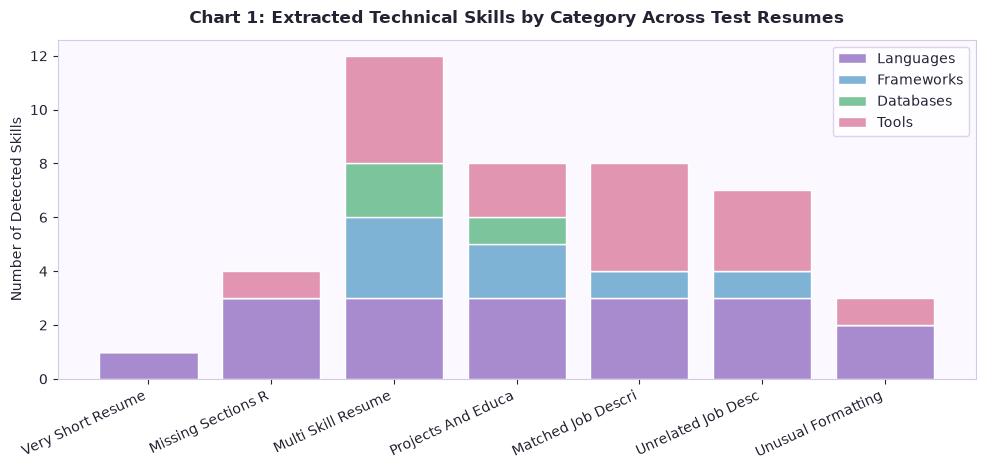

In [3]:
valid_cases = [tc for tc in TEST_CASES if tc["resume"].strip()]
categories = list(SKILL_TAXONOMY.keys())
cat_counts = {cat: [] for cat in categories}
case_labels = []

for tc in valid_cases:
    case_labels.append(tc["name"].split("_", 1)[1].replace("_", " ").title()[:18])
    extracted = engine.extract_skills(tc["resume"])
    for cat in categories:
        cat_counts[cat].append(len(extracted[cat]))

# Chart 1: Stacked Bar Chart of Extracted Skills by Category (Pastel Palette)
fig, ax = plt.subplots(figsize=(10, 4.8))
bottom = np.zeros(len(valid_cases))
colors = [PASTEL_LAVENDER, PASTEL_BLUE, PASTEL_GREEN, PASTEL_PINK]

for cat, color in zip(categories, colors):
    vals = np.array(cat_counts[cat])
    ax.bar(case_labels, vals, bottom=bottom, label=cat.title(), color=color, edgecolor="#FFFFFF")
    bottom += vals

ax.set_title("Chart 1: Extracted Technical Skills by Category Across Test Resumes", fontweight="bold", pad=12)
ax.set_ylabel("Number of Detected Skills")
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D5C9E8")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 7. Resume Section Extraction
We run `engine.analyze()` on all test cases and inspect which sections (`education`, `experience`, `projects`, `skills`, `certifications`) are detected as `present`, `incomplete`, or `missing`.


In [4]:
analyses = []
for tc in TEST_CASES:
    res = engine.analyze(tc["resume"], tc["jd"] or None)
    analyses.append((tc["name"], res))
    if res["valid"]:
        sec_summary = {k: v["status"] for k, v in res["section_assessment"].items()}
        print(f"{tc['name']}: score={res['overall_score']} | sections={sec_summary}")
    else:
        print(f"{tc['name']}: valid=False | error={res['error']}")


1_empty_resume: valid=False | error=Resume text must be a non-empty string.
2_very_short_resume: score=12 | sections={'education': 'missing', 'experience': 'missing', 'projects': 'missing', 'skills': 'missing', 'certifications': 'missing'}
3_missing_sections_resume: score=30 | sections={'education': 'missing', 'experience': 'missing', 'projects': 'missing', 'skills': 'present', 'certifications': 'missing'}
4_multi_skill_resume: score=76 | sections={'education': 'missing', 'experience': 'present', 'projects': 'missing', 'skills': 'present', 'certifications': 'missing'}
5_projects_and_education_resume: score=73 | sections={'education': 'present', 'experience': 'missing', 'projects': 'present', 'skills': 'incomplete', 'certifications': 'missing'}


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

6_matched_job_description: score=90 | sections={'education': 'incomplete', 'experience': 'present', 'projects': 'present', 'skills': 'present', 'certifications': 'missing'}
7_unrelated_job_description: score=43 | sections={'education': 'incomplete', 'experience': 'missing', 'projects': 'present', 'skills': 'incomplete', 'certifications': 'missing'}
8_unusual_formatting_and_repetition: score=44 | sections={'education': 'missing', 'experience': 'present', 'projects': 'missing', 'skills': 'incomplete', 'certifications': 'missing'}


## 8. Semantic Similarity Analysis (MiniLM vs. TF-IDF Baseline)
We compare `all-MiniLM-L6-v2` cosine similarity against a lexical `TF-IDF` baseline across:
1. Matched Job Description (`6_matched_job_description`)
2. Unrelated Job Description (`7_unrelated_job_description`)
3. Unusual Formatting & Repetition (`8_unusual_formatting_and_repetition`)
4. Paraphrase Pair (different vocabulary, same frontend engineering meaning)


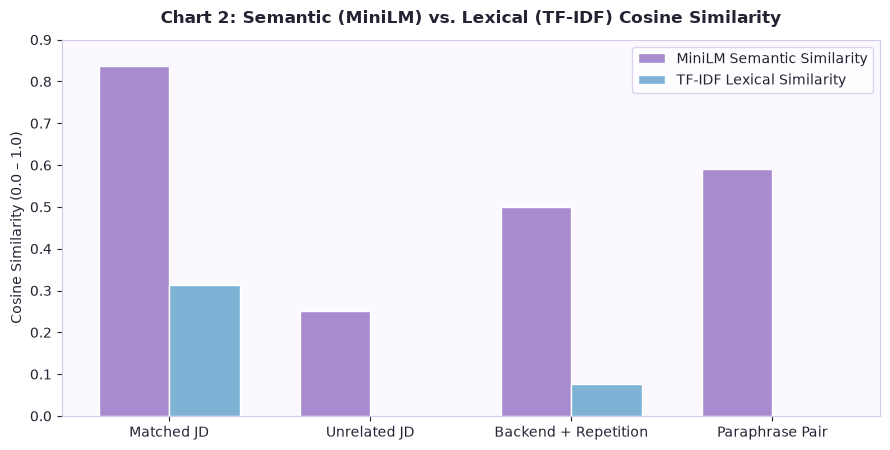

In [5]:
paraphrase_resume = (
    "Built client-side single page web applications, styled mobile-friendly layouts, "
    "and fetched JSON data from backend web services."
)
paraphrase_jd = (
    "Looking for a frontend developer to create responsive browser interfaces and "
    "integrate HTTP API endpoints."
)
para_res = engine.analyze(paraphrase_resume, paraphrase_jd)

sim_labels = ["Matched JD", "Unrelated JD", "Backend + Repetition", "Paraphrase Pair"]
sem_scores = []
lex_scores = []

for name, res in analyses:
    if name in {"6_matched_job_description", "7_unrelated_job_description", "8_unusual_formatting_and_repetition"}:
        sem_scores.append(res["semantic_relevance"]["overall_similarity"])
        lex_scores.append(res["semantic_relevance"]["lexical_tfidf_similarity"])

sem_scores.append(para_res["semantic_relevance"]["overall_similarity"])
lex_scores.append(para_res["semantic_relevance"]["lexical_tfidf_similarity"])

# Chart 2: Semantic (MiniLM) vs Lexical (TF-IDF) Similarity
x = np.arange(len(sim_labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.bar(x - width/2, sem_scores, width, label="MiniLM Semantic Similarity", color=PASTEL_LAVENDER, edgecolor="#FFFFFF")
ax.bar(x + width/2, lex_scores, width, label="TF-IDF Lexical Similarity", color=PASTEL_BLUE, edgecolor="#FFFFFF")

ax.set_title("Chart 2: Semantic (MiniLM) vs. Lexical (TF-IDF) Cosine Similarity", fontweight="bold", pad=12)
ax.set_ylabel("Cosine Similarity (0.0 – 1.0)")
ax.set_ylim(0, 0.9)
ax.set_xticks(x)
ax.set_xticklabels(sim_labels)
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D5C9E8")
plt.tight_layout()
plt.show()


## 9. Resume Scoring Methodology
Every score is decomposed into transparent rubric components (`structure_score`, `skills_score`, `semantic_relevance_score`, `quality_score`).


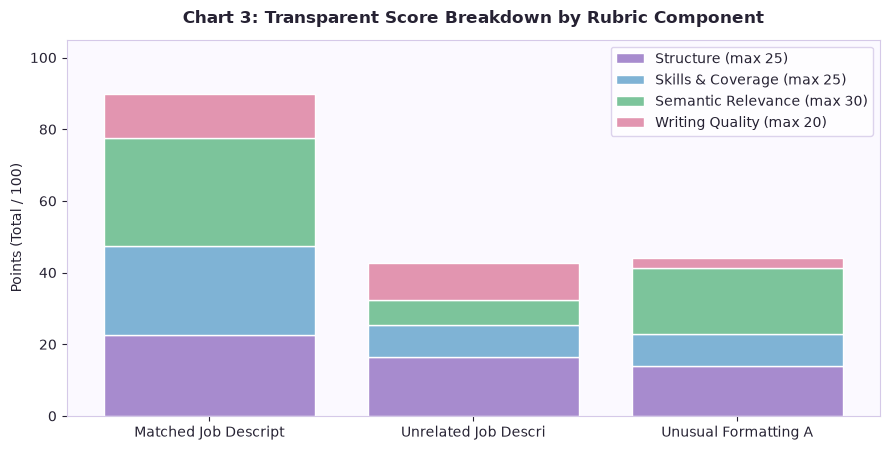

In [6]:
jd_cases = [(name, res) for name, res in analyses if res.get("valid") and res.get("semantic_relevance")]
labels = [name.split("_", 1)[1].replace("_", " ").title()[:20] for name, _ in jd_cases]
s_pts = [res["score_breakdown"]["structure_score"] for _, res in jd_cases]
k_pts = [res["score_breakdown"]["skills_score"] for _, res in jd_cases]
m_pts = [res["score_breakdown"]["semantic_relevance_score"] for _, res in jd_cases]
q_pts = [res["score_breakdown"]["quality_score"] for _, res in jd_cases]

# Chart 3: Score Breakdown by Rubric Component (Pastel Palette)
fig, ax = plt.subplots(figsize=(9, 4.6))
b1 = np.array(s_pts)
b2 = np.array(k_pts)
b3 = np.array(m_pts)
b4 = np.array(q_pts)

ax.bar(labels, b1, label="Structure (max 25)", color=PASTEL_LAVENDER, edgecolor="#FFFFFF")
ax.bar(labels, b2, bottom=b1, label="Skills & Coverage (max 25)", color=PASTEL_BLUE, edgecolor="#FFFFFF")
ax.bar(labels, b3, bottom=b1+b2, label="Semantic Relevance (max 30)", color=PASTEL_GREEN, edgecolor="#FFFFFF")
ax.bar(labels, b4, bottom=b1+b2+b3, label="Writing Quality (max 20)", color=PASTEL_PINK, edgecolor="#FFFFFF")

ax.set_title("Chart 3: Transparent Score Breakdown by Rubric Component", fontweight="bold", pad=12)
ax.set_ylabel("Points (Total / 100)")
ax.set_ylim(0, 105)
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D5C9E8", loc="upper right")
plt.tight_layout()
plt.show()


## 10. Evaluation and Error Analysis
We run the formal evaluation suite (`run_evaluation()`) to verify all 8 functional test cases and inspect edge-case behavior.


In [7]:
eval_report = run_evaluation()
print(f"All {eval_report['functional_cases_passed']} functional cases passed in {eval_report['total_runtime_seconds']}s.")
print("Paraphrase comparison:", json.dumps(eval_report["paraphrase_comparison"], indent=2))


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

All 8 functional cases passed in 2.147s.
Paraphrase comparison: {
  "semantic_minilm_similarity": 0.5901,
  "lexical_tfidf_similarity": 0.0,
  "semantic_advantage": 0.5901
}


## 11. Example Resume Analysis
Full structured output for the matched Junior Frontend Developer test case.


In [8]:
matched_res = dict(analyses)["6_matched_job_description"]
print(json.dumps(matched_res, indent=2))


{
  "valid": true,
  "model_used": "sentence-transformers/all-MiniLM-L6-v2",
  "overall_score": 90,
  "score_breakdown": {
    "structure_score": 22.5,
    "structure_max": 25,
    "skills_score": 25.0,
    "skills_max": 25,
    "semantic_relevance_score": 30.0,
    "semantic_relevance_max": 30,
    "quality_score": 12.2,
    "quality_max": 20
  },
  "contact_info": {
    "has_email": true,
    "has_phone": false,
    "has_links": true,
    "has_any_contact": true
  },
  "section_assessment": {
    "education": {
      "status": "incomplete",
      "has_explicit_header": true,
      "word_count": 5
    },
    "experience": {
      "status": "present",
      "has_explicit_header": true,
      "word_count": 29
    },
    "projects": {
      "status": "present",
      "has_explicit_header": true,
      "word_count": 12
    },
    "skills": {
      "status": "present",
      "has_explicit_header": true,
      "word_count": 9
    },
    "certifications": {
      "status": "missing",
      "

## 12. Model and Artifact Export
We save the pretrained `all-MiniLM-L6-v2` model locally to `ml/ResumeAnalyzer/models/all-MiniLM-L6-v2` for offline/fast local inference and export `skill_taxonomy.json` to `ml/ResumeAnalyzer/artifacts/`.


In [9]:
models_dir = Path("models/all-MiniLM-L6-v2")
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

model = engine._get_model()
model.save(str(models_dir))

(artifacts_dir / "skill_taxonomy.json").write_text(json.dumps(SKILL_TAXONOMY, indent=2), encoding="utf-8")
print("Saved local model to:", models_dir.resolve())
print("Saved skill taxonomy & evaluation_report.json to:", artifacts_dir.resolve())


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved local model to: D:\CareerPilot AI\ml\ResumeAnalyzer\models\all-MiniLM-L6-v2
Saved skill taxonomy & evaluation_report.json to: D:\CareerPilot AI\ml\ResumeAnalyzer\artifacts


## 13. Final Observations and Limitations
- **Strengths:** Semantic similarity (`all-MiniLM-L6-v2`) clearly separates matched vs. unrelated job descriptions and outperforms TF-IDF on paraphrased frontend descriptions. Structural and quality checks catch missing sections, vague bullet starters, and repeated verbs without exposing PII.
- **Limitations:**
  1. Section parsing relies on line-level headings; multi-column PDF text extraction with scrambled line order can reduce section detection accuracy.
  2. Skill extraction uses a curated taxonomy; emerging or niche tools outside `SKILL_TAXONOMY` are not categorized unless added.
  3. No supervised ground-truth dataset of human-graded resumes is used, so scores reflect transparent rubric alignment rather than hiring probability.
